# Install dependencies

In [1]:
# Install required libraries
%pip install tensorflow numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Import required libraries

In [2]:
# Import TensorFlow
import tensorflow as tf

# Import Keras
from tensorflow import keras

# Import required layers
from tensorflow.keras import layers

# Import NumPy
import numpy as np

# Import Matplotlib
import matplotlib.pyplot as plt

# Import classification metrics
from sklearn.metrics import classification_report, confusion_matrix


# Load CIFAR-10 dataset

In [3]:
# Load CIFAR-10 training and testing data
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Display training image shape
print("Training Images:", x_train.shape)

# Display training labels shape
print("Training Labels:", y_train.shape)

# Display testing image shape
print("Testing Images:", x_test.shape)

# Display testing labels shape
print("Testing Labels:", y_test.shape)

# Display total training images
print("Total Training Images:", len(x_train))

# Display total testing images
print("Total Testing Images:", len(x_test))

Training Images: (50000, 32, 32, 3)
Training Labels: (50000, 1)
Testing Images: (10000, 32, 32, 3)
Testing Labels: (10000, 1)
Total Training Images: 50000
Total Testing Images: 10000


# Define CIFAR-10 class names

In [4]:
# Define the ten image categories
class_names = [
    'Airplane',
    'Automobile',
    'Bird',
    'Cat',
    'Deer',
    'Dog',
    'Frog',
    'Horse',
    'Ship',
    'Truck'
]

# Display class names
print("CIFAR-10 Classes:")

for i, name in enumerate(class_names):
    print(i, ":", name)

CIFAR-10 Classes:
0 : Airplane
1 : Automobile
2 : Bird
3 : Cat
4 : Deer
5 : Dog
6 : Frog
7 : Horse
8 : Ship
9 : Truck


# Display sample images

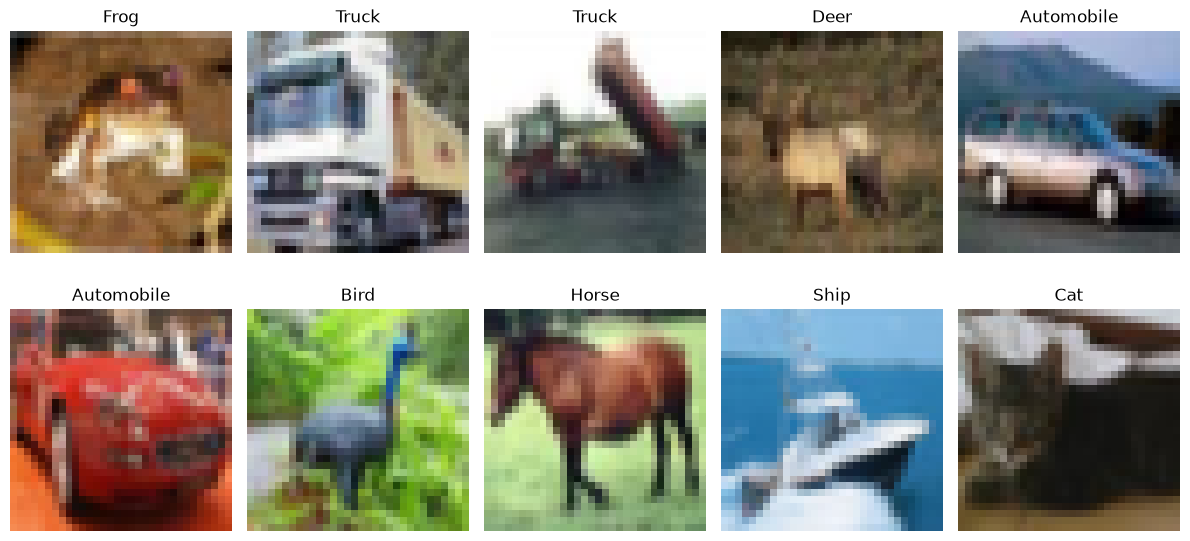

In [5]:
# Create figure
plt.figure(figsize=(12, 6))

# Display first 10 training images
for i in range(10):

    # Create subplot
    plt.subplot(2, 5, i + 1)

    # Display image
    plt.imshow(x_train[i])

    # Display image class
    plt.title(class_names[int(y_train[i][0])])

    # Hide axis
    plt.axis('off')

# Adjust spacing
plt.tight_layout()

# Display images
plt.show()

# Preprocess image data

In [6]:
# Normalize training images between 0 and 1
x_train = x_train.astype('float32') / 255.0

# Normalize testing images
x_test = x_test.astype('float32') / 255.0

# Convert labels into one-dimensional arrays
y_train = y_train.flatten()
y_test = y_test.flatten()

# Display processed image shape
print("Training Data Shape:", x_train.shape)

# Display pixel value range
print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())

# Display successful message
print("Image preprocessing completed!")

Training Data Shape: (50000, 32, 32, 3)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Image preprocessing completed!


# Define CNN model architecture

In [7]:
# Create sequential CNN model
model = keras.Sequential([

    # Define input image shape
    keras.Input(shape=(32, 32, 3)),

    # First convolution layer with 32 filters
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),

    # Reduce image dimensions
    layers.MaxPooling2D((2, 2)),

    # Second convolution layer with 64 filters
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),

    # Reduce image dimensions
    layers.MaxPooling2D((2, 2)),

    # Third convolution layer with 128 filters
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),

    # Flatten feature maps into one-dimensional vector
    layers.Flatten(),

    # Fully connected layer with 128 neurons
    layers.Dense(128, activation='relu'),

    # Dropout to reduce overfitting
    layers.Dropout(0.5),

    # Output layer with 10 classes
    layers.Dense(10, activation='softmax')

])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 8192)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       1,048,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

# Compile the CNN model

In [17]:
# Compile the CNN model
model.compile(

    # Use Adam optimizer
    optimizer='adam',

    # Use sparse categorical crossentropy
    loss='sparse_categorical_crossentropy',

    # Measure classification accuracy
    metrics=['accuracy']

)

# Display compilation message
print("CNN Model compiled successfully!")

CNN Model compiled successfully!


# Train the CNN model

In [18]:
# Train the CNN model
history = model.fit(

    # Training images
    x_train,

    # Training labels
    y_train,

    # Number of epochs
    epochs=10,

    # Number of images processed per batch
    batch_size=64,

    # Use 20% training data for validation
    validation_split=0.2,

    # Display training progress
    verbose=1

)

# Display completion message
print("CNN Model training completed!")

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.8213 - loss: 0.4913 - val_accuracy: 0.7538 - val_loss: 0.7859
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.8350 - loss: 0.4544 - val_accuracy: 0.7603 - val_loss: 0.7766
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.8465 - loss: 0.4228 - val_accuracy: 0.7534 - val_loss: 0.8287
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.8568 - loss: 0.3891 - val_accuracy: 0.7408 - val_loss: 0.8655
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.8698 - loss: 0.3520 - val_accuracy: 0.7515 - val_loss: 0.8796
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.8780 - loss: 0.3293 - val_accuracy: 0.7516 - val_loss: 0.9233
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.8845 - loss: 0.3153 - val_accuracy: 0.7552 - val_loss: 0.9598
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.8921 - loss: 0.2904 - 

# Evaluate model performance

In [19]:
# Evaluate model using testing data
test_loss, test_accuracy = model.evaluate(x_test, y_test)

# Display testing loss
print("Test Loss:", test_loss)

# Display testing accuracy
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7427 - loss: 1.1106
Test Loss: 1.1105786561965942
Test Accuracy: 74.26999807357788 %


# Plot training and validation accuracy

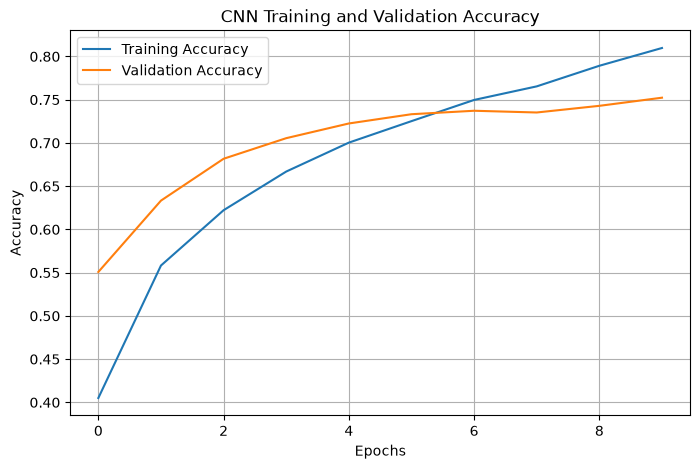

In [11]:
# Create accuracy graph
plt.figure(figsize=(8, 5))

# Plot training accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')

# Plot validation accuracy
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

# Add graph title
plt.title('CNN Training and Validation Accuracy')

# Add X-axis label
plt.xlabel('Epochs')

# Add Y-axis label
plt.ylabel('Accuracy')

# Display legend
plt.legend()

# Display grid
plt.grid(True)

# Show graph
plt.show()

# Plot training and validation loss

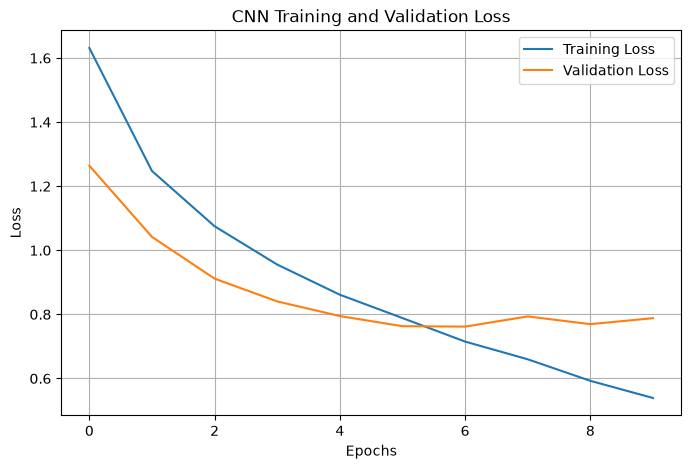

In [12]:
# Create loss graph
plt.figure(figsize=(8, 5))

# Plot training loss
plt.plot(history.history['loss'], label='Training Loss')

# Plot validation loss
plt.plot(history.history['val_loss'], label='Validation Loss')

# Add graph title
plt.title('CNN Training and Validation Loss')

# Add X-axis label
plt.xlabel('Epochs')

# Add Y-axis label
plt.ylabel('Loss')

# Display legend
plt.legend()

# Display grid
plt.grid(True)

# Show graph
plt.show()

# Predict image classes

In [13]:
# Predict first 10 testing images
predictions = model.predict(x_test[:10])

# Find class with highest probability
predicted_labels = np.argmax(predictions, axis=1)

# Display actual and predicted labels
for i in range(10):

    print(
        "Actual:", class_names[y_test[i]],
        "| Predicted:", class_names[predicted_labels[i]]
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
Actual: Cat | Predicted: Cat
Actual: Ship | Predicted: Ship
Actual: Ship | Predicted: Ship
Actual: Airplane | Predicted: Airplane
Actual: Frog | Predicted: Frog
Actual: Frog | Predicted: Frog
Actual: Automobile | Predicted: Automobile
Actual: Frog | Predicted: Deer
Actual: Cat | Predicted: Cat
Actual: Automobile | Predicted: Automobile


# Display predicted images

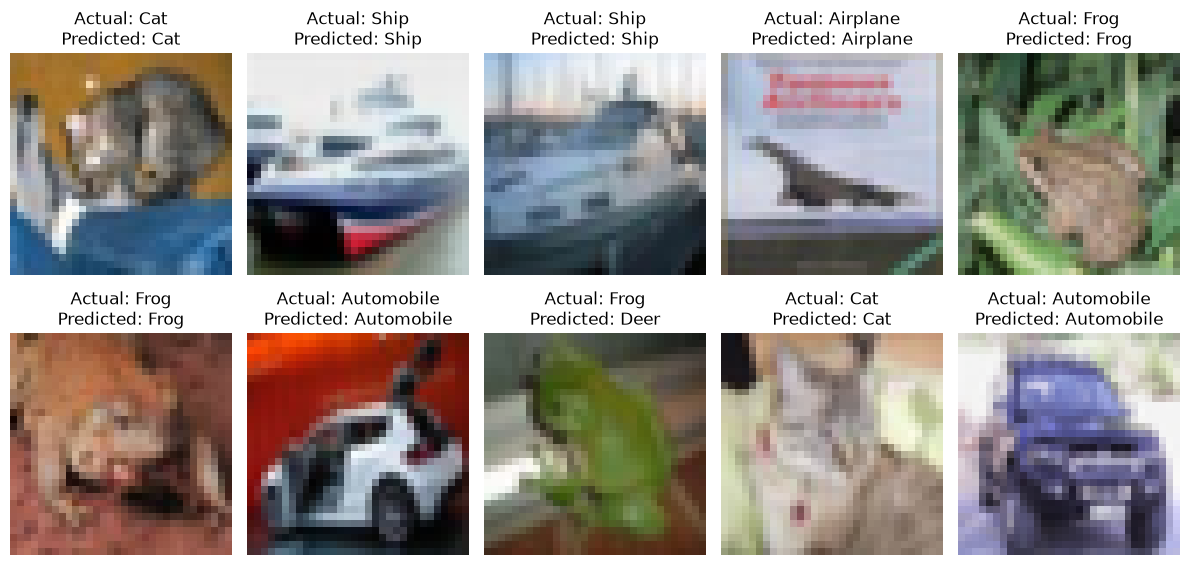

In [14]:
# Create figure
plt.figure(figsize=(12, 6))

# Display first 10 testing images
for i in range(10):

    # Create subplot
    plt.subplot(2, 5, i + 1)

    # Display image
    plt.imshow(x_test[i])

    # Get actual and predicted class names
    actual = class_names[y_test[i]]
    predicted = class_names[predicted_labels[i]]

    # Display prediction
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    # Hide axis
    plt.axis('off')

# Adjust layout
plt.tight_layout()

# Display output
plt.show()

# Classification report